In [31]:
%load_ext pyspecdata.ipy
from itertools import cycle
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = cycle(prop_cycle.by_key()['color'])

The pyspecdata.ipy extension is already loaded. To reload it, use:
  %reload_ext pyspecdata.ipy


### Overview

This code is splitted into multiple parts.
1. cooling
        load data
        get peak ranges
        Above transition (High Temperature)
            calculate tau
            plot tau
        Below Transition (low temperature) 
            calculate tau
            plot tau
2. Subsequently heating
        load data
        get peak ranges
        Above transition (High Temperature)
            calculate tau
            plot tau
        Below Transition (low temperature) 
            calculate tau
            plot tau
plot tau for both cooling and reheating

# load data

Loading data and selecting only first harmonics
also sort by temperature, since we've learned about pyspec bug with backwards data

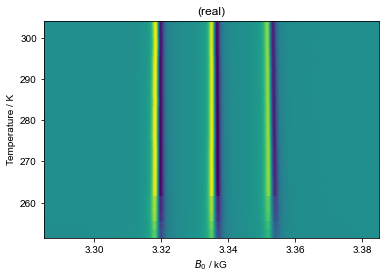

In [32]:
d_cooling = find_file("241205_TS_dodec_W20_11mM_run3.DSC", exp_type="francklab_esr/romana") #cooling
d_cooling= d_cooling.chunk_auto('harmonic','harmonic')['harmonic', 0]['phase',0]
d_cooling.reorder('Temperature').sort('Temperature')
d_cooling.pcolor()

## Check field ranges for the three lines

<!-- let's use 300 and 220 K as examples for where the peaks are located in the "high-temp" vs. "low-temp" limits
 -->
<!-- RS: I will set above 260 K and below 260 K -->

## Cooling 

Text(0.5, 1.0, 'peak C')

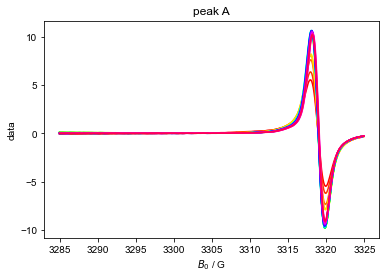

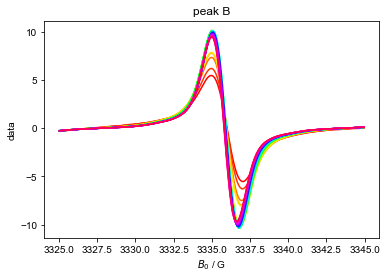

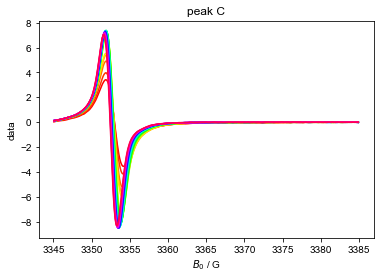

In [33]:
figure()
plot(d_cooling['Temperature':(250,None)]['$B_0$':(3285,3325)]) # peak A above transition
title("peak A")
figure()
plot(d_cooling['Temperature':(250,None)]['$B_0$':(3325,3345)]) # peak B above transition
title("peak B")
figure()
plot(d_cooling['Temperature':(250,None)]['$B_0$':(3345,3385)]) # peak C above transition
title("peak C")

# Pick the Peaks and Calculate the Correlation times

The first cell here only operates over a limited temperature range.

In [34]:
correlation_time_cooling = {}

correlation time is 3.5191131200032106e-10
correlation time is 3.19329777515775e-10
correlation time is 2.681627067099089e-10
correlation time is 2.419607211714297e-10
correlation time is 2.2116975482876133e-10
correlation time is 2.0819325139847382e-10
correlation time is 2.0067681336101568e-10
correlation time is 1.8792720055289016e-10
correlation time is 1.81896435407936e-10
correlation time is 1.7339075435253113e-10
correlation time is 1.6873836052184125e-10
correlation time is 1.6017794206486654e-10
correlation time is 1.575449642593873e-10
correlation time is 1.5197842907914998e-10
correlation time is 1.5013246649198112e-10
correlation time is 1.4622379185619414e-10
correlation time is 1.4466920062178369e-10
correlation time is 1.3815585261444364e-10
correlation time is 1.3375423319342942e-10
correlation time is 1.3235094322619383e-10
correlation time is 1.3169228876068143e-10
correlation time is 1.2818967246241518e-10
correlation time is 1.307812021429047e-10
correlation time is

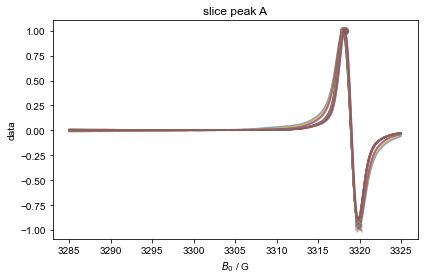

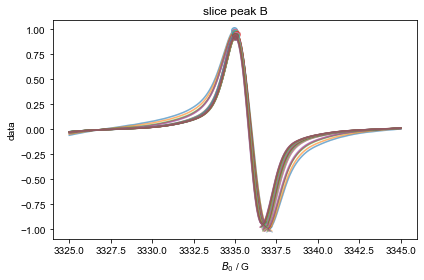

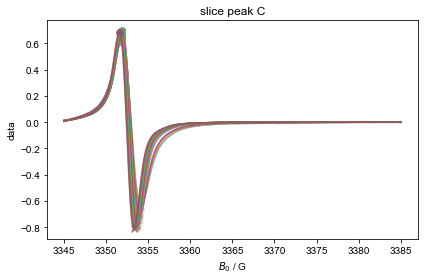

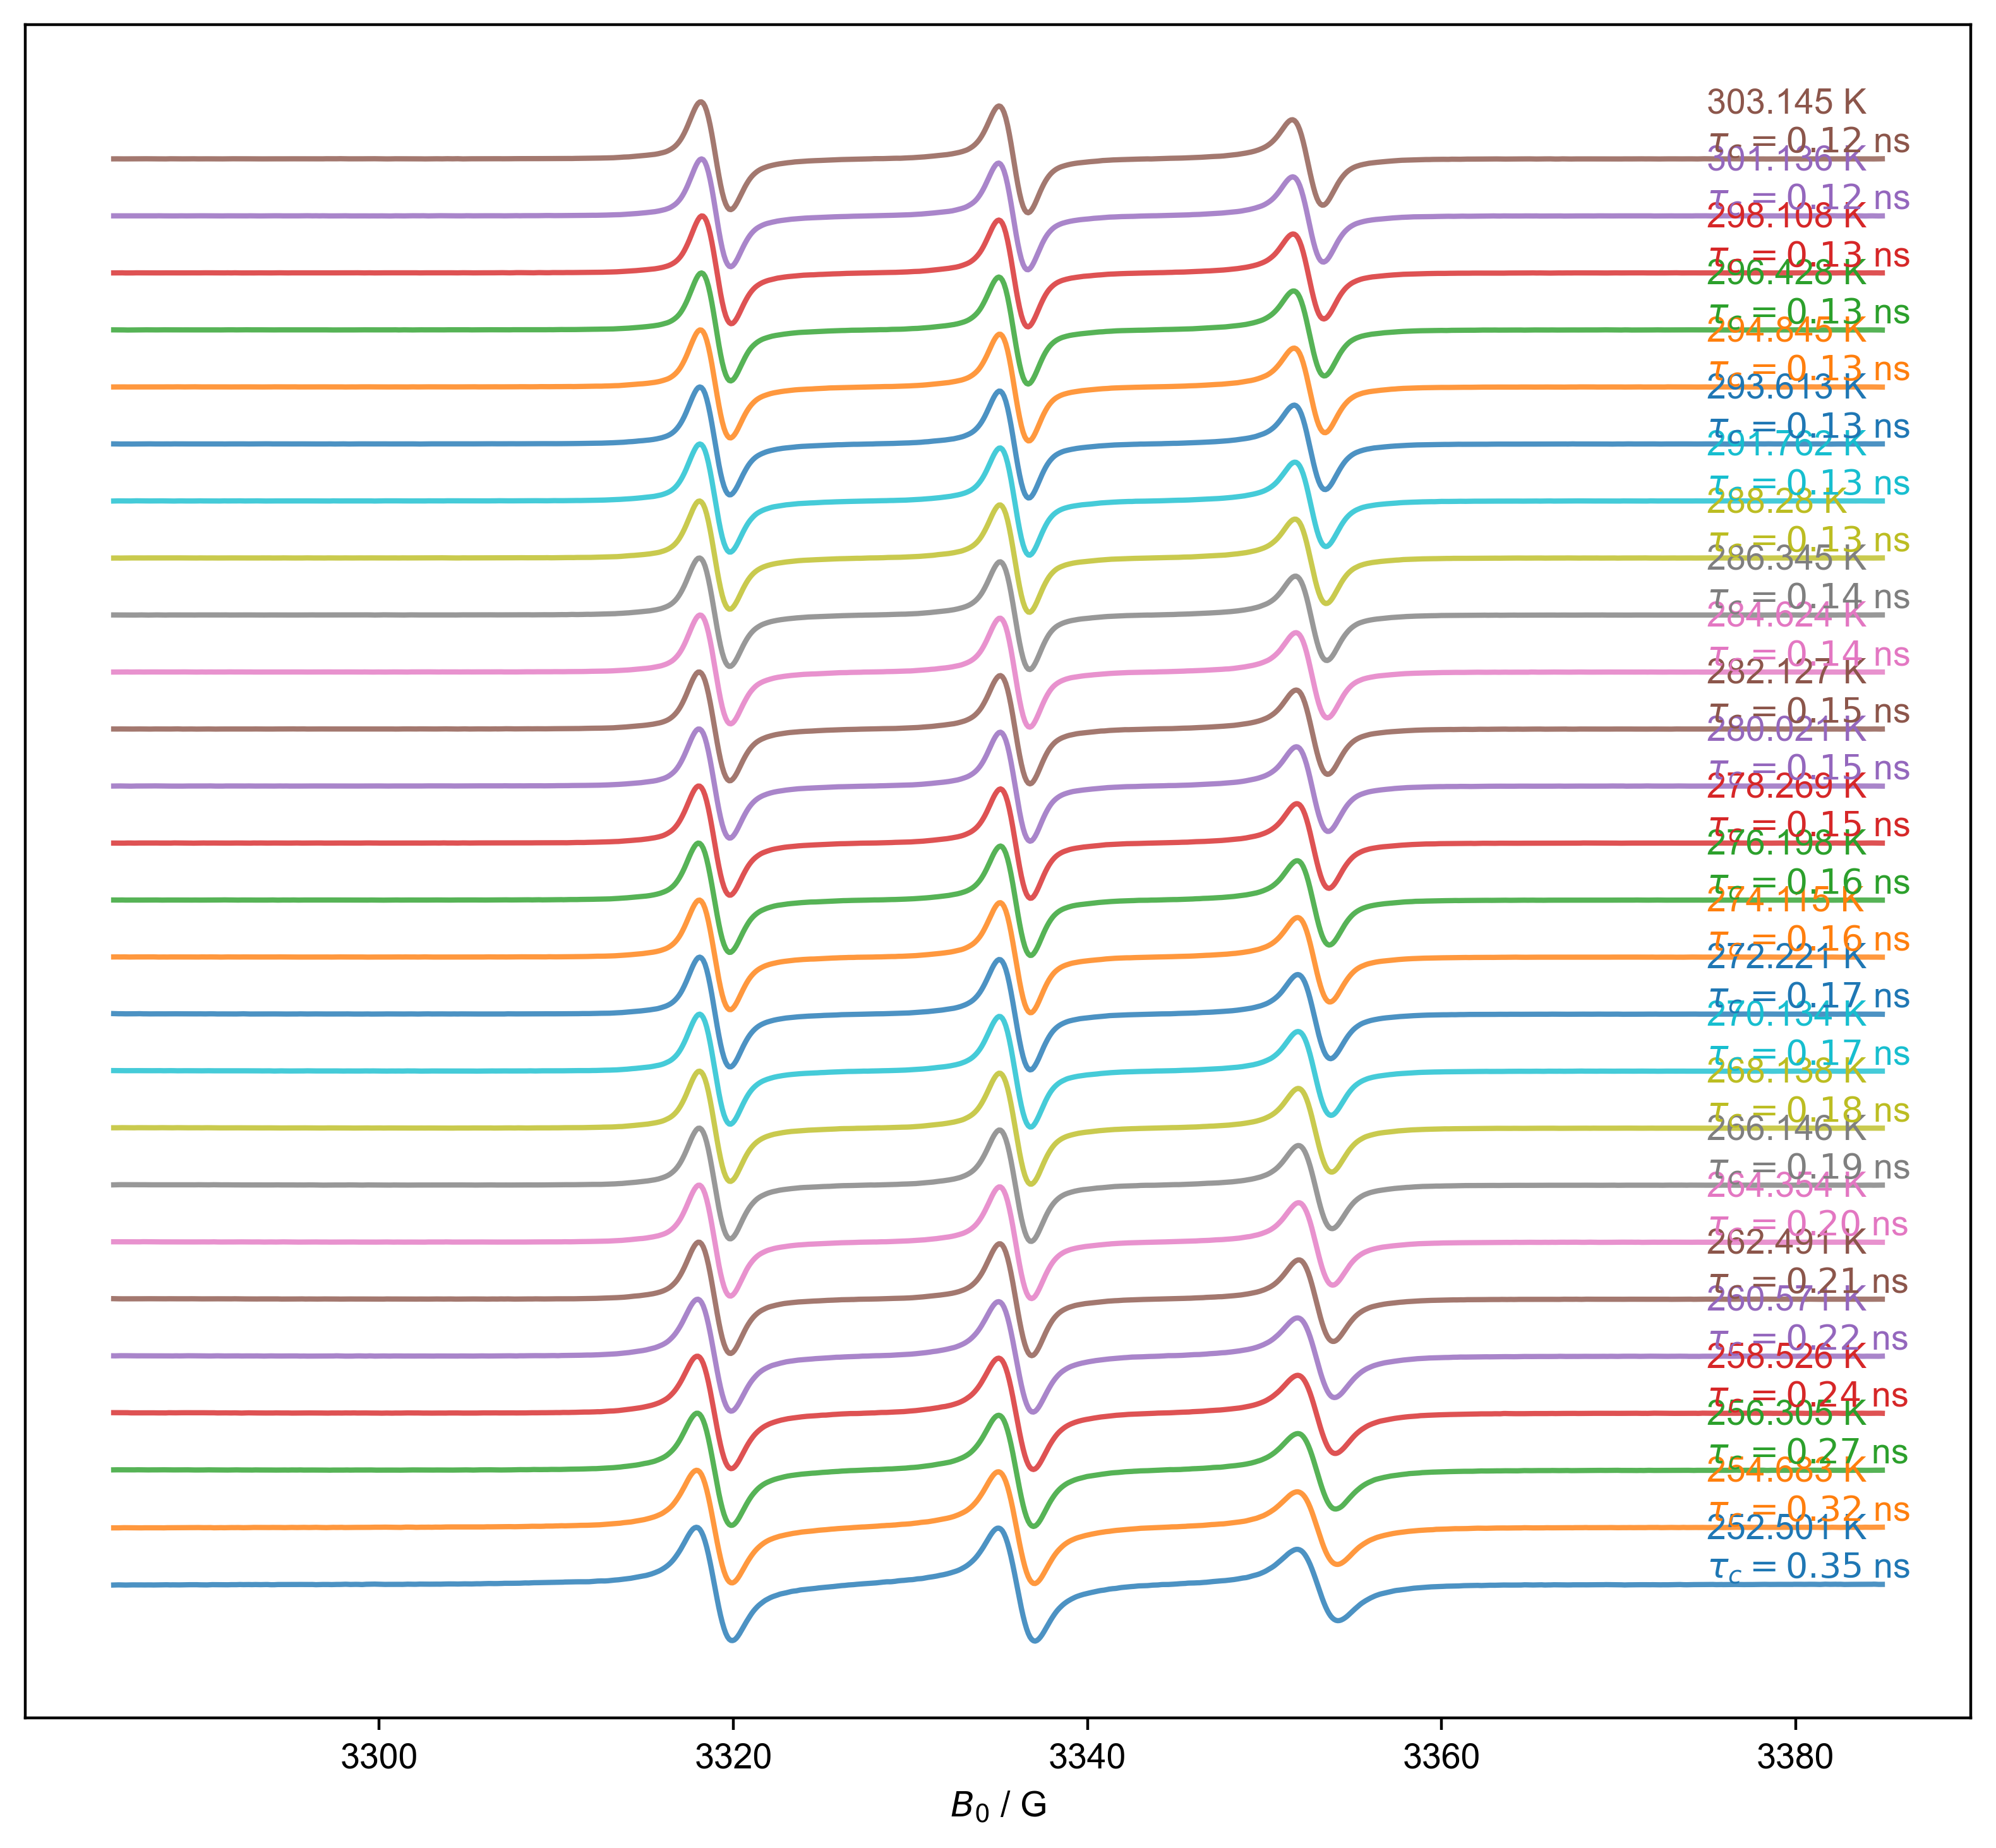

In [35]:
all_data= d_cooling['Temperature':(None,None)] 
x_counter = 0
j_counter = 0
with figlist_var() as fl: # RS: when to use with?
    for this_temp in all_data['Temperature']:
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data["Temperature": this_temp]
        d /= d.max().item() # RS: when to use .item ?
        peak_data = {}
        # next, we define the ranges for our peaks
        if this_temp >= 240:
            peak_A_range = (3285,3325)
            peak_B_range = (3325,3345)
            peak_C_range = (3345,3385)
        for peak_range,peak_name in [
            (peak_A_range,'A'),
            (peak_B_range,'B'),
            (peak_C_range,'C'),
        ]:
            fl.next(f'slice peak {peak_name}') # move to the figure called "slice peak A", "slice peak B", etc.
            plt.title(fl.current) # this shouldn't be needed -- just says use the current figure name as the title
            peak_spline_fn = d['$B_0$':peak_range].spline_lambda() # create a function that will make a spline curve
#             peak = peak.spline_lambda(s_multiplier=spline_multiplier)(np.linspace(*tuple(B_range + (500,)))
                
            peak = peak_spline_fn(linspace(*tuple(peak_range+(500,)))) # make a smooth, high-res curve of our peak, using the spline
            plot(peak, c=this_color,alpha=0.2)
            peak = d['$B_0$':peak_range].spline_lambda(s_multiplier=1e-4)(linspace(*tuple(peak_range+(500,))))
            plot(peak,c=this_color,alpha=0.5) # overwrite with a smoothed one
            max_B0 = peak.C.argmax().item() # this one returns an nddata, while the argmin returns something that
            #                                 looks like a dictionary
            min_B0 = peak.C.argmin()['$B_0$']  # give the x axis values for the peaks -- there's a bug where
            #                                    this and the previous line should be similar, but are not
            # {{{ here we are builing up a dictionary that has all the values we need to calculate the correlation time
            peak_data[peak_name+'max'] = peak['$B_0$':max_B0].item() # return the y value, and store as value of key Amax, Bmax, Cmax
            peak_data[peak_name+'min'] = peak['$B_0$':min_B0].item()
            peak_data[peak_name+'maxB0'] = max_B0 # set the key AmaxB0, BmaxB0, etc. to max_B0
            peak_data[peak_name+'minB0'] = min_B0
            # }}}
            # {{{ explicitly check that the points that correspond to these values show up in the right place
            plot(peak_data[peak_name+'maxB0'],peak_data[peak_name+'max'],'o',c=this_color,alpha=0.5)
            plot(peak_data[peak_name+'minB0'],peak_data[peak_name+'min'],'x',c=this_color,alpha=0.5)
            # }}}
        fl.next('pub_fig',figsize=(8,12/(1+sqrt(5))*2), dpi=400) ## use golden ratio for figure size
        fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False) ### x_counter offsets the curves
        # next, I have a dictionary that contains all the values I need to calculate my correlation time
        # this line plugs those values into the expression for my correlation time:
        # basically, it assumes that all of the words correspond to keys of my dictionary, and it substitutes
        # them with the corresponding values
        tau_c = eval("6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",{'sqrt':sqrt},peak_data)
        # above is equivalent to: 6.51e-10*(peak_data['BminB0']-peak_data['BmaxB0']*(sqrt((...
        print("correlation time is",tau_c)
        correlation_time_cooling[label_str] = tau_c 
        plt.gca().text(
                3375,
                x_counter,
                label_str+f' K\n$\\tau_c={tau_c/1e-9:0.2f}$ ns',
                transform=plt.gca().transData,
                va='bottom',
                ha='left',
                color=this_color,
                )
        x_counter += 1
        #xlim(3375,3550)
        j_counter += 1.1
    fl.next('pub_fig')
    plt.title('')
    plt.ylabel('')
    plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
                          labelleft=False, labelbottom=True,
                          labelright=False)

In [36]:
correlation_time_cooling

{'252.501': 3.5191131200032106e-10,
 '254.683': 3.19329777515775e-10,
 '256.305': 2.681627067099089e-10,
 '258.526': 2.419607211714297e-10,
 '260.571': 2.2116975482876133e-10,
 '262.491': 2.0819325139847382e-10,
 '264.354': 2.0067681336101568e-10,
 '266.146': 1.8792720055289016e-10,
 '268.138': 1.81896435407936e-10,
 '270.134': 1.7339075435253113e-10,
 '272.221': 1.6873836052184125e-10,
 '274.115': 1.6017794206486654e-10,
 '276.198': 1.575449642593873e-10,
 '278.269': 1.5197842907914998e-10,
 '280.021': 1.5013246649198112e-10,
 '282.127': 1.4622379185619414e-10,
 '284.624': 1.4466920062178369e-10,
 '286.345': 1.3815585261444364e-10,
 '288.28': 1.3375423319342942e-10,
 '291.762': 1.3235094322619383e-10,
 '293.613': 1.3169228876068143e-10,
 '294.845': 1.2818967246241518e-10,
 '296.428': 1.307812021429047e-10,
 '298.108': 1.2571776429917588e-10,
 '301.136': 1.235762913504928e-10,
 '303.145': 1.2200887924715291e-10}

In [37]:
temp_cooling= np.array([float(j) for j in correlation_time_cooling.keys()])
tau_cooling = np.array(list(correlation_time_cooling.values()))

## Reheating 

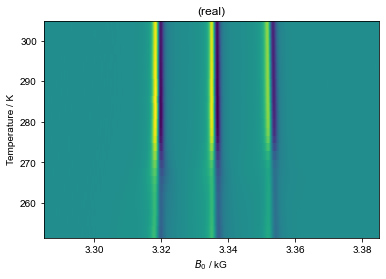

In [38]:
d_reheating = find_file("241205_TS_dodec_W20_11mM_run4.DSC", exp_type="francklab_esr/romana") #reheating subsequently
d_reheating= d_reheating.chunk_auto('harmonic','harmonic')['harmonic', 0]['phase',0]
d_reheating.reorder('Temperature').sort('Temperature')
d_reheating.pcolor()

Text(0.5, 1.0, 'peak C')

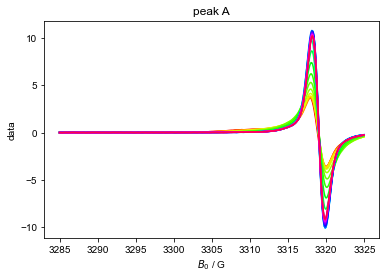

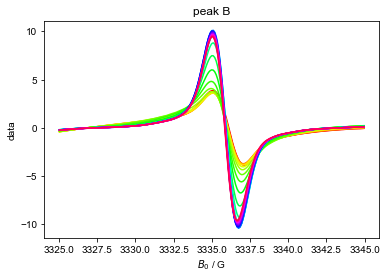

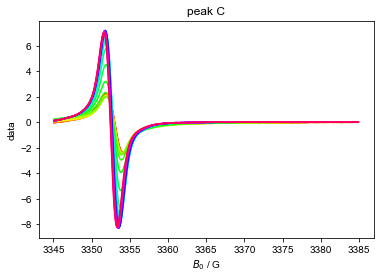

In [39]:
figure()
plot(d_reheating['Temperature':(250,None)]['$B_0$':(3285,3325)]) # peak A above transition
title("peak A")
figure()
plot(d_reheating['Temperature':(250,None)]['$B_0$':(3325,3345)]) # peak B above transition
title("peak B")
figure()
plot(d_reheating['Temperature':(250,None)]['$B_0$':(3345,3385)]) # peak C above transition
title("peak C")

#### RS: All transition

In [40]:
correlation_time_reheating = {}

correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation time is 1.2200887924715291e-10
correlation

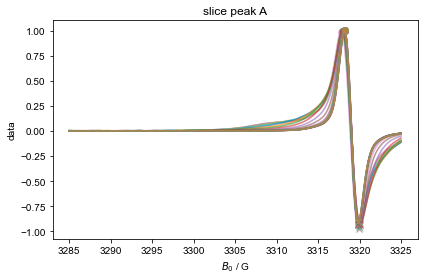

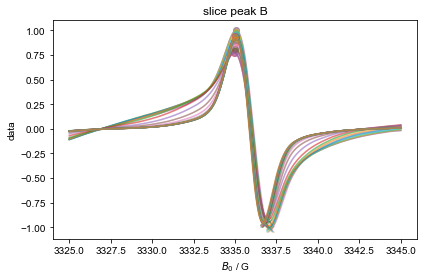

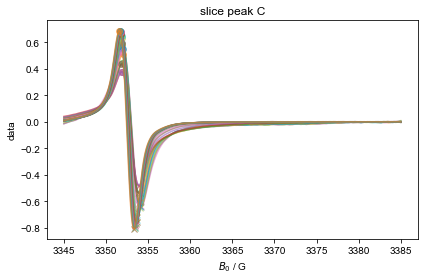

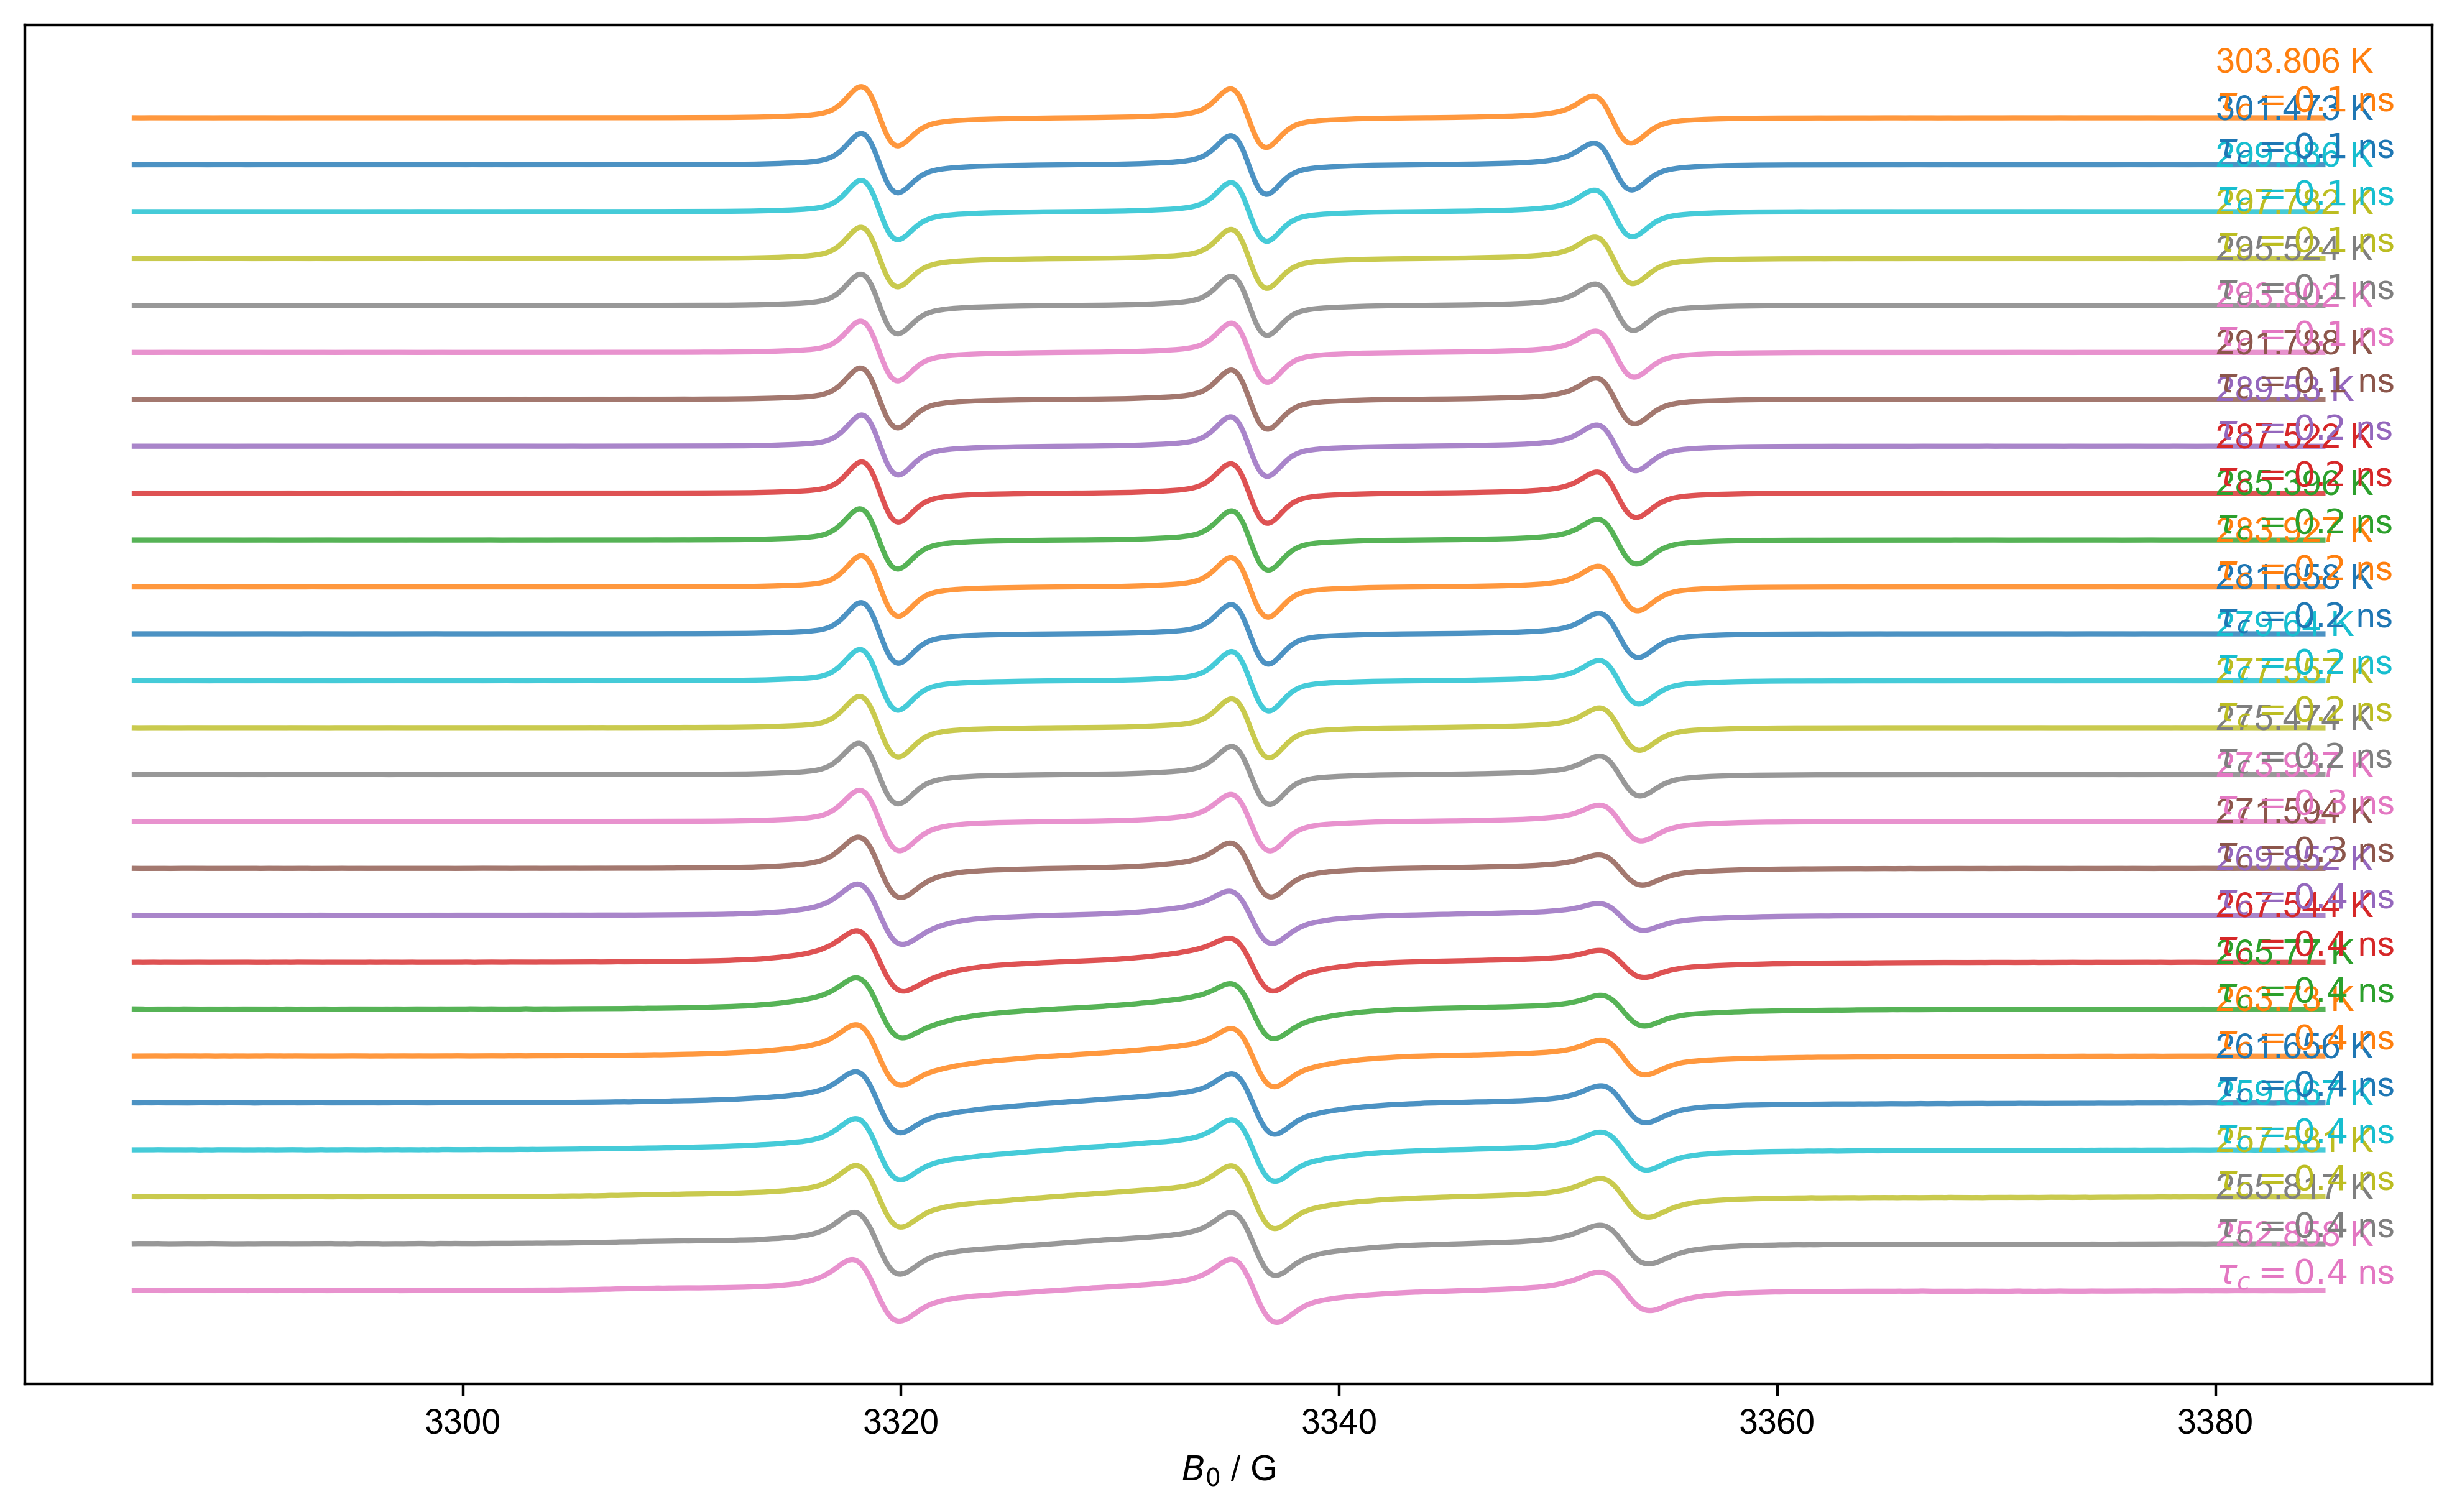

In [41]:
all_data_reheating= d_reheating['Temperature':(None,None)] # let's start just with high temp
x_counter = 0
j_counter = 0
with figlist_var() as fl: ### why with???
    for this_temp in all_data_reheating['Temperature']:
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data_reheating["Temperature": this_temp]
        d /= d.max().item() ### RS item??? normalize??
        peak_data_reheating = {}
        # next, we define the ranges for our peaks
        # note that we can replace this with an if ... else statement
        # to allow different peak slices for different temperatures
        if this_temp >= 240:
            peak_A_range = (3285,3325)
            peak_B_range = (3325,3345)
            peak_C_range = (3345,3385)
#         elif this_temp >= 250:
#             peak_A_range = (3320,3358)
#             peak_B_range = (3358,3382)
#             peak_C_range = (3376,3403)            
#         else:
#             peak_A_range = (3320,3358)
#             peak_B_range = (3358,3382)
#             peak_C_range = (3382,3406)
        for peak_range,peak_name in [
            (peak_A_range,'A'),
            (peak_B_range,'B'),
            (peak_C_range,'C'),
        ]:
            fl.next(f'slice peak {peak_name}') # move to the figure called "slice peak A", "slice peak B", etc.
            plt.title(fl.current) # this shouldn't be needed -- just says use the current figure name as the title
            peak_spline_fn = d['$B_0$':peak_range].spline_lambda() # create a function that will make a spline curve
            peak = peak_spline_fn(linspace(*tuple(peak_range+(500,)))) # make a smooth, high-res curve of our peak, using the spline
            plot(peak,c=this_color,alpha=0.2)
            peak = d['$B_0$':peak_range].spline_lambda(s_multiplier=1e-4)(linspace(*tuple(peak_range+(500,))))
            plot(peak,c=this_color,alpha=0.5) # overwrite with a smoothed one
            max_B0 = peak.C.argmax().item() # this one returns an nddata, while the argmin returns something that
            #                                 looks like a dictionary
            min_B0 = peak.C.argmin()['$B_0$']  # give the x axis values for the peaks -- there's a bug where
            #                                    this and the previous line should be similar, but are not
            # {{{ here we are builing up a dictionary that has all the values we need to calculate the correlation time
            peak_data_reheating[peak_name+'max'] = peak['$B_0$':max_B0].item() # return the y value, and store as value of key Amax, Bmax, Cmax
            peak_data_reheating[peak_name+'min'] = peak['$B_0$':min_B0].item()
            peak_data_reheating[peak_name+'maxB0'] = max_B0 # set the key AmaxB0, BmaxB0, etc. to max_B0
            peak_data_reheating[peak_name+'minB0'] = min_B0
            # }}}
            # {{{ explicitly check that the points that correspond to these values show up in the right place
            plot(peak_data_reheating[peak_name+'maxB0'],peak_data_reheating[peak_name+'max'],'o',c=this_color,alpha=0.5)
            plot(peak_data_reheating[peak_name+'minB0'],peak_data_reheating[peak_name+'min'],'x',c=this_color,alpha=0.5)
            # }}}
        fl.next('pub_fig',figsize=(10,10/(1+sqrt(5))*2), dpi=400) ## use golden ratio for figure size
        fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False) ### x_counter offsets the curves
        # next, I have a dictionary that contains all the values I need to calculate my correlation time
        # this line plugs those values into the expression for my correlation time:
        # basically, it assumes that all of the words correspond to keys of my dictionary, and it substitutes
        # them with the corresponding values
        tau_c_reheating = eval("6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",{'sqrt':sqrt},peak_data_reheating)
        # above is equivalent to: 6.51e-10*(peak_data['BminB0']-peak_data['BmaxB0']*(sqrt((...
        print("correlation time is",tau_c)
        correlation_time_reheating[label_str] = tau_c_reheating 
        plt.gca().text(
                3380,
                x_counter,
                label_str+f' K\n$\\tau_c={tau_c_reheating/1e-9:0.1f}$ ns',
                transform=plt.gca().transData,
                va='bottom',
                ha='left',
                color=this_color,
                )
        x_counter += 1.5
        #xlim(3375,3550)
        j_counter += 1
    fl.next('pub_fig')
    plt.title('')
    plt.ylabel('')
    plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
                          labelleft=False, labelbottom=True,
                          labelright=False)

In [42]:
correlation_time_reheating

{'252.858': 3.9783090768961003e-10,
 '255.817': 3.814461048501364e-10,
 '257.581': 3.649731969447844e-10,
 '259.667': 3.573619940803812e-10,
 '261.656': 3.556106644533676e-10,
 '263.73': 3.534196693908197e-10,
 '265.77': 3.886140466500138e-10,
 '267.544': 4.493055372909041e-10,
 '269.852': 4.2325680690271924e-10,
 '271.594': 3.447551906396998e-10,
 '273.937': 2.6353869022375557e-10,
 '275.474': 2.1024610966186895e-10,
 '277.557': 1.899695626869904e-10,
 '279.64': 1.7759196183101058e-10,
 '281.658': 1.7156662014904796e-10,
 '283.927': 1.62499306870911e-10,
 '285.396': 1.606969840399957e-10,
 '287.522': 1.59048205115671e-10,
 '289.53': 1.506936961651528e-10,
 '291.788': 1.4380698471231235e-10,
 '293.802': 1.4117559299527727e-10,
 '295.524': 1.3166574863988306e-10,
 '297.782': 1.280474704734982e-10,
 '299.886': 1.2589123502662037e-10,
 '301.473': 1.2132765627448582e-10,
 '303.806': 1.226643500843407e-10}

In [43]:
temp_reheating= np.array([float(j) for j in correlation_time_reheating.keys()])
tau_reheating = np.array(list(correlation_time_reheating.values()))

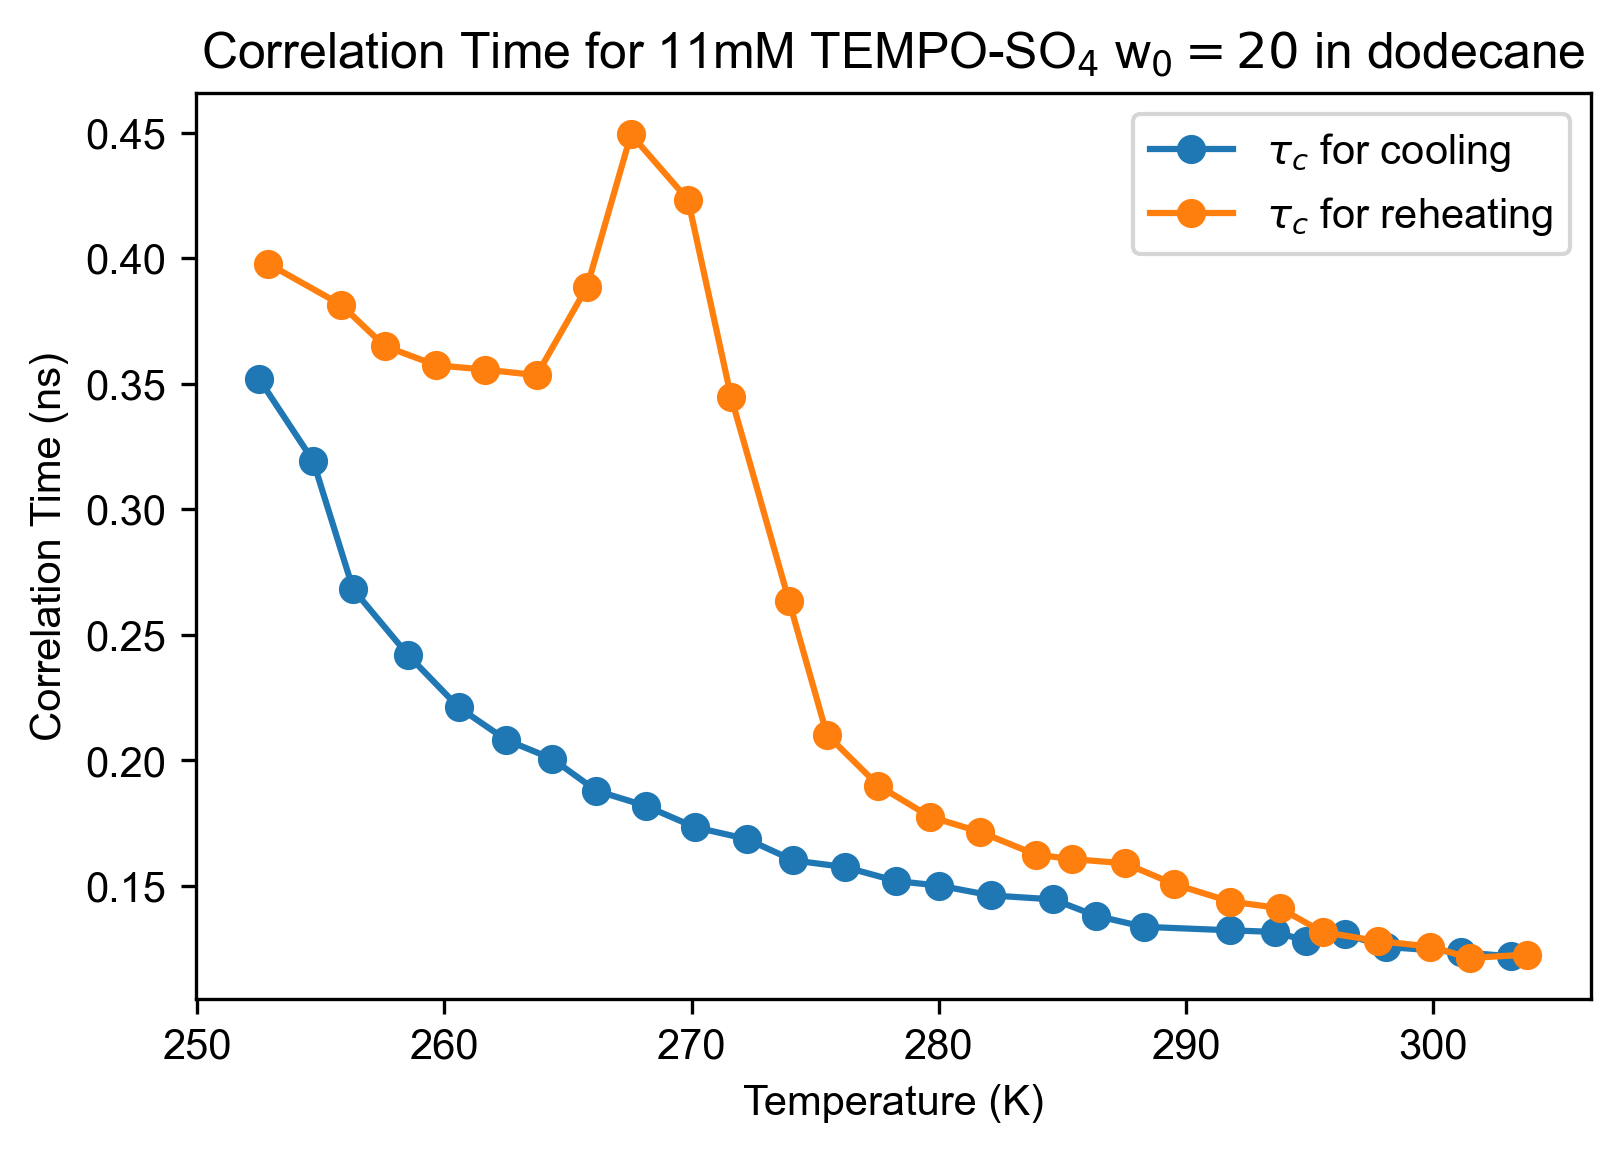

In [44]:
# Tau caculation
figure(dpi=300, figsize=(6,4))
plot(temp_cooling, tau_cooling/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for cooling")
plot(temp_reheating, tau_reheating/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for reheating")
legend()
# xlim(250,285)
xlabel('Temperature (K)')
ylabel('Correlation Time (ns)')
title('Correlation Time for 11mM TEMPO-SO$_4$ w$_0=20$ in dodecane')
show()

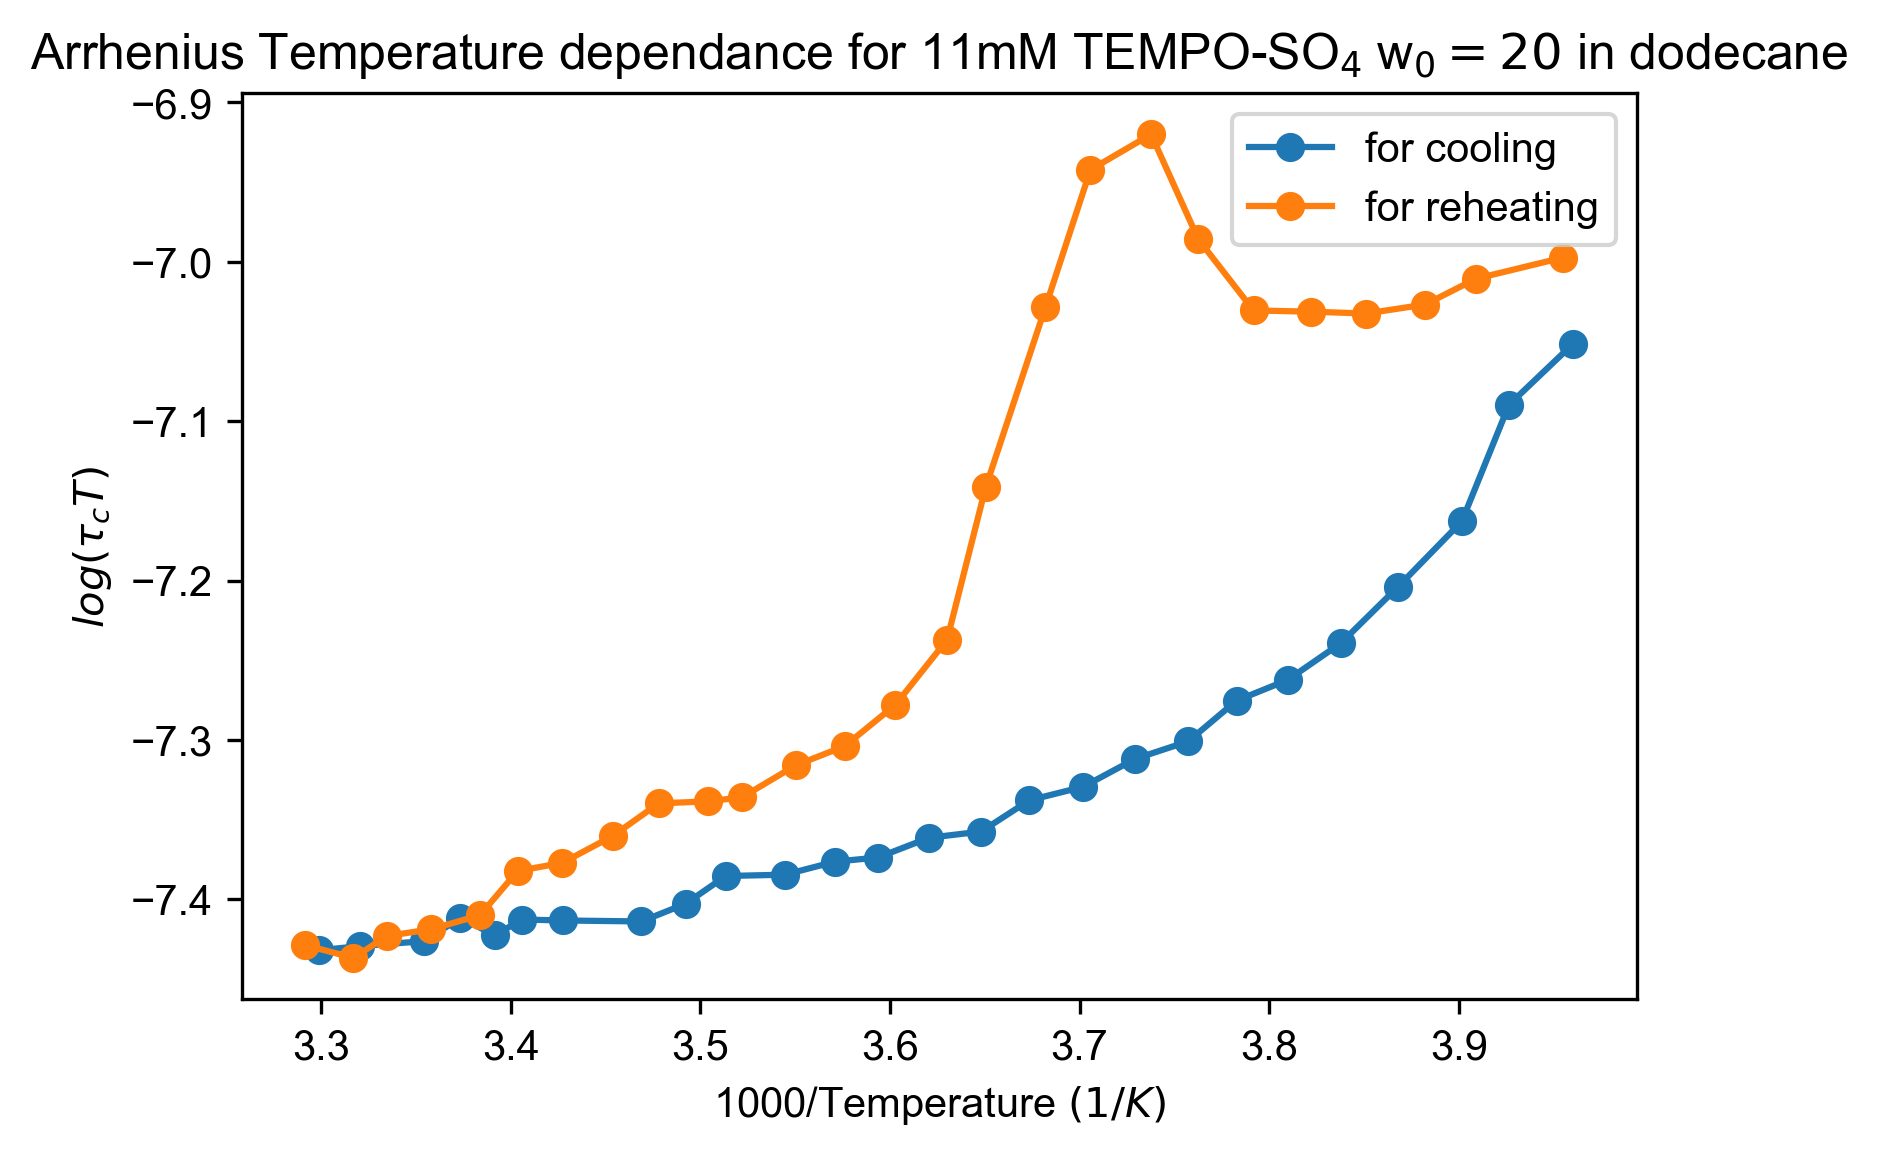

In [45]:
# Arrhenius  
figure(dpi=300, figsize=(6,4))
plot(1000/temp_cooling, log10(tau_cooling*temp_cooling), linestyle='-',  marker='o', label=r"for cooling")
plot(1000/temp_reheating, log10(tau_reheating*temp_reheating), linestyle='-',  marker='o', label=r"for reheating")
legend()
# xlim(2.9,4.1)
xlabel(r"1000/Temperature $(1/K)$")
ylabel(r"$log(\tau_cT)$")
title('Arrhenius Temperature dependance for 11mM TEMPO-SO$_4$ w$_0=20$ in dodecane')
show()

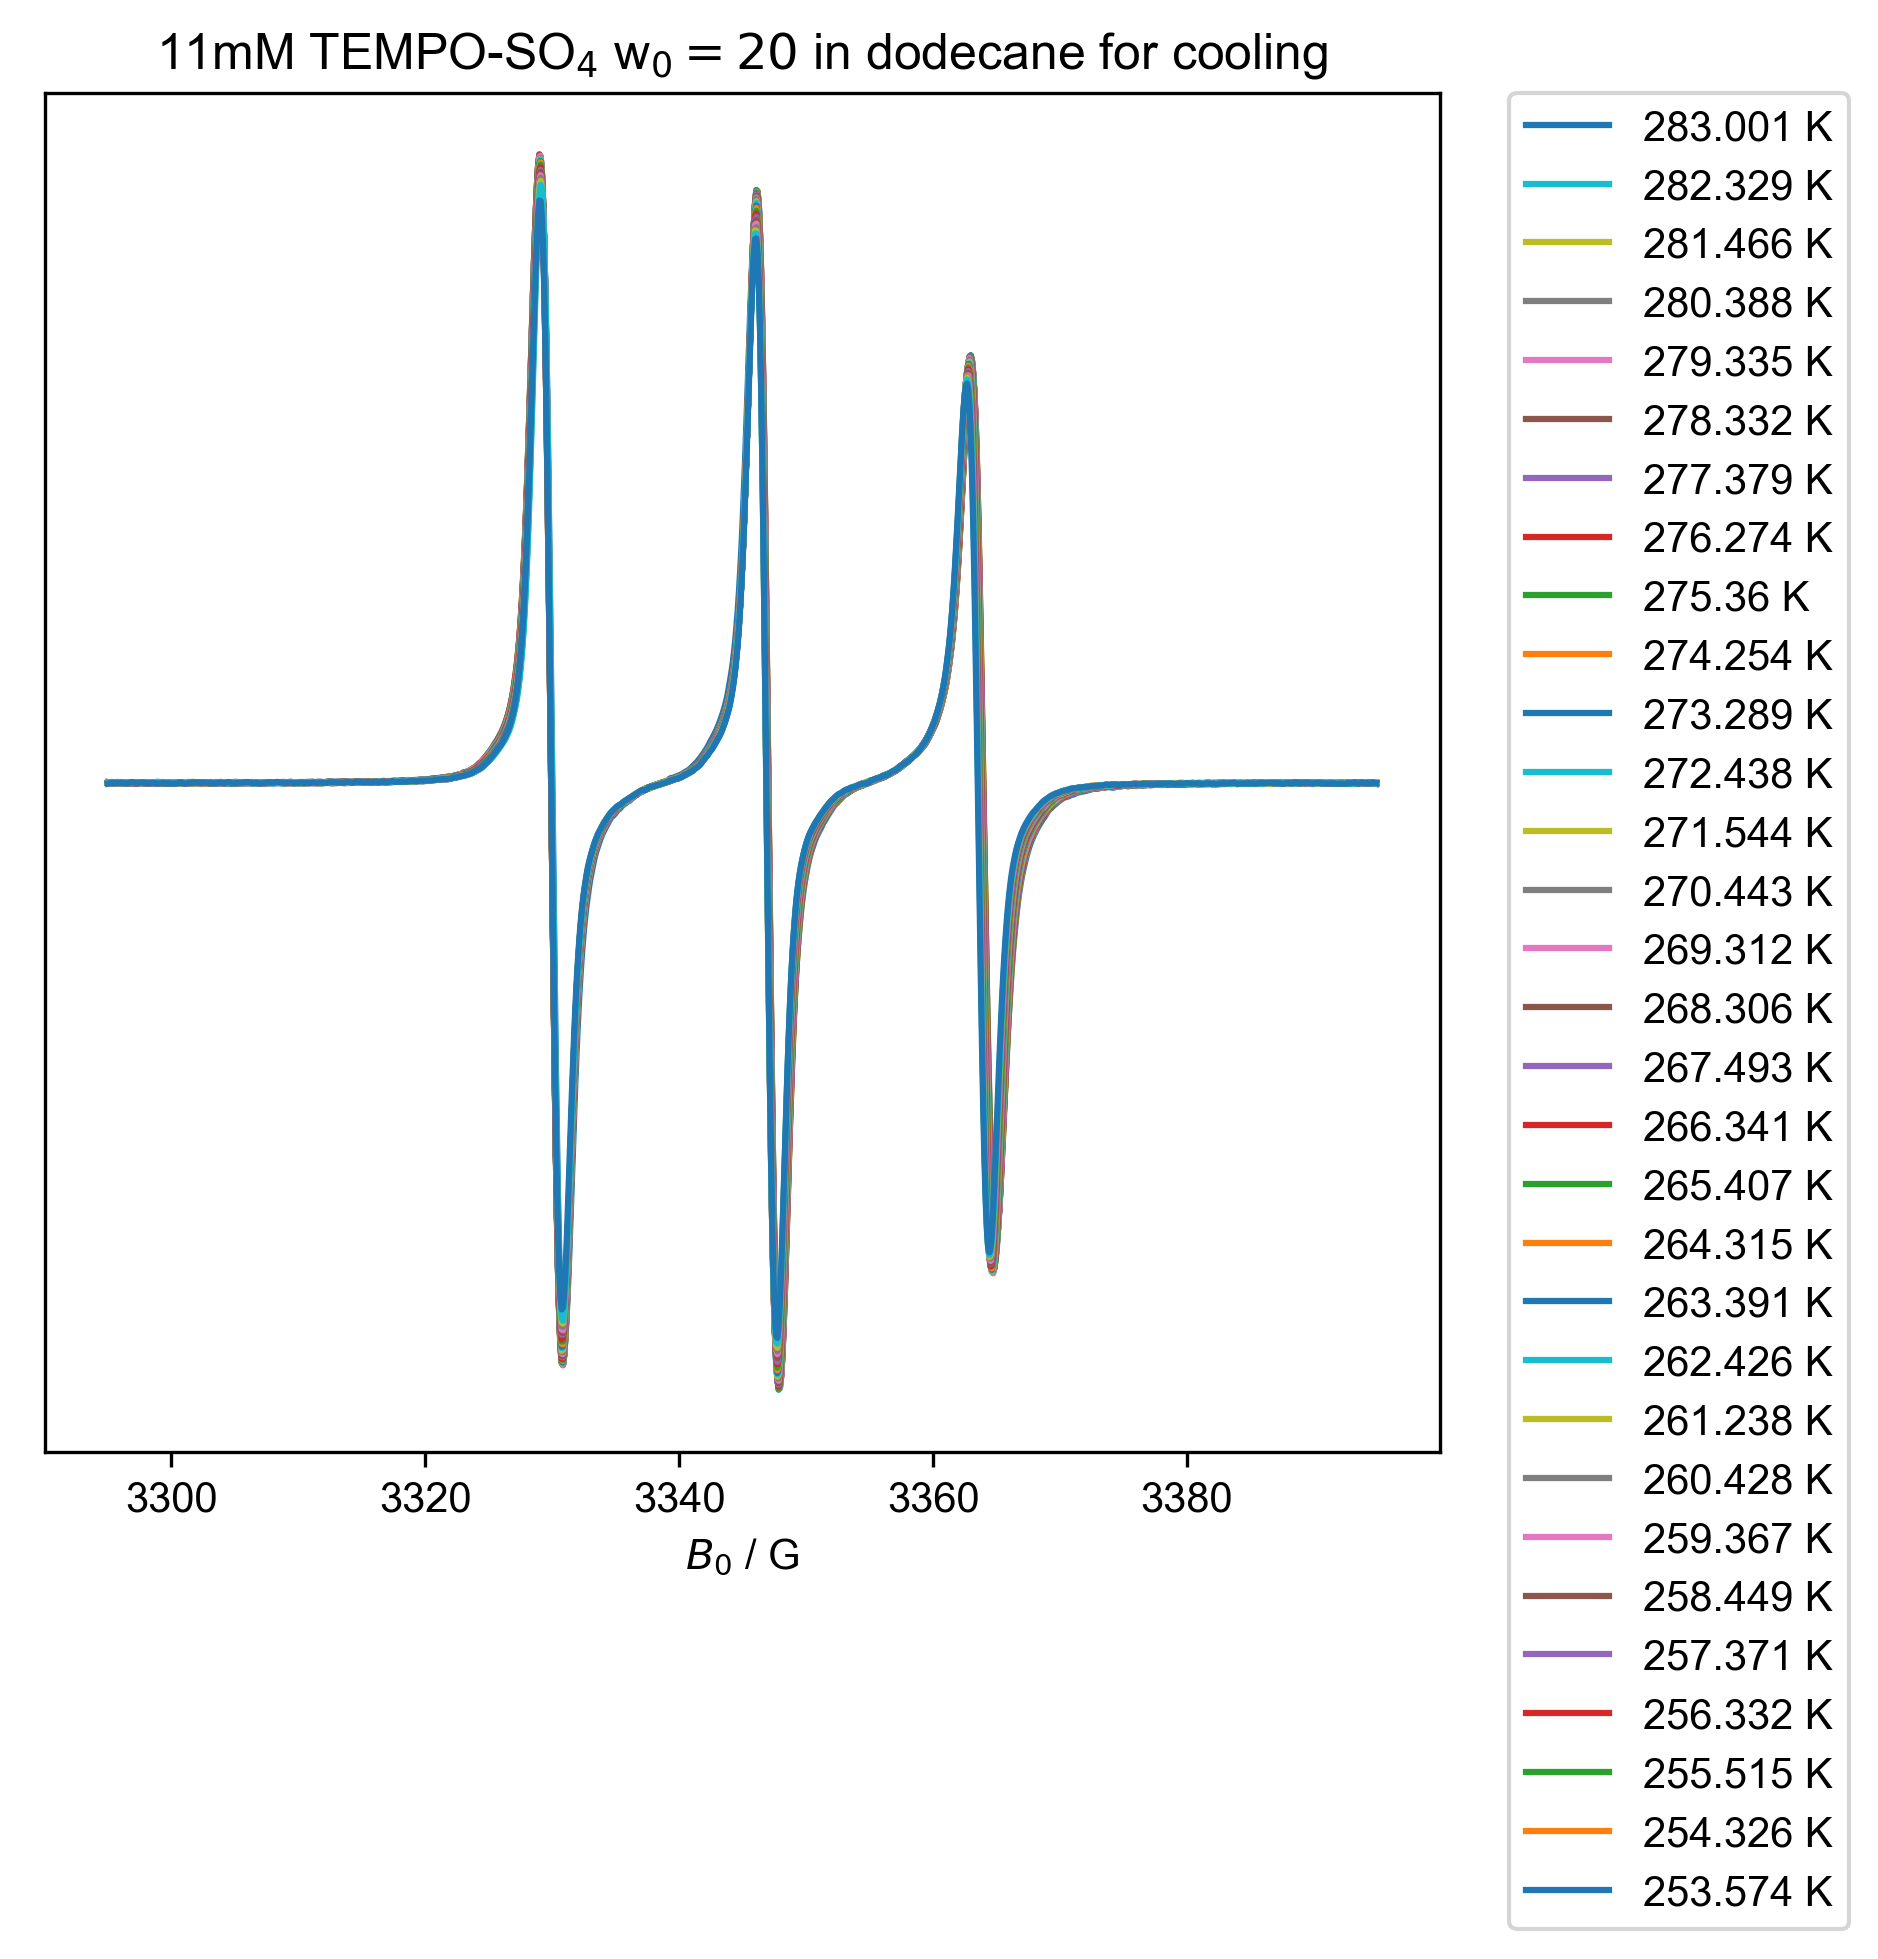

In [16]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("11mM TEMPO-SO$_4$ w$_0=20$ in dodecane for cooling", (200, 300))
 ]:
    this_d1 = d_cooling["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
#         offset += 2.2
#         offset += this_d1["Temperature", temp_ithis_dx].max()*1.8
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
#     fancy_legend()

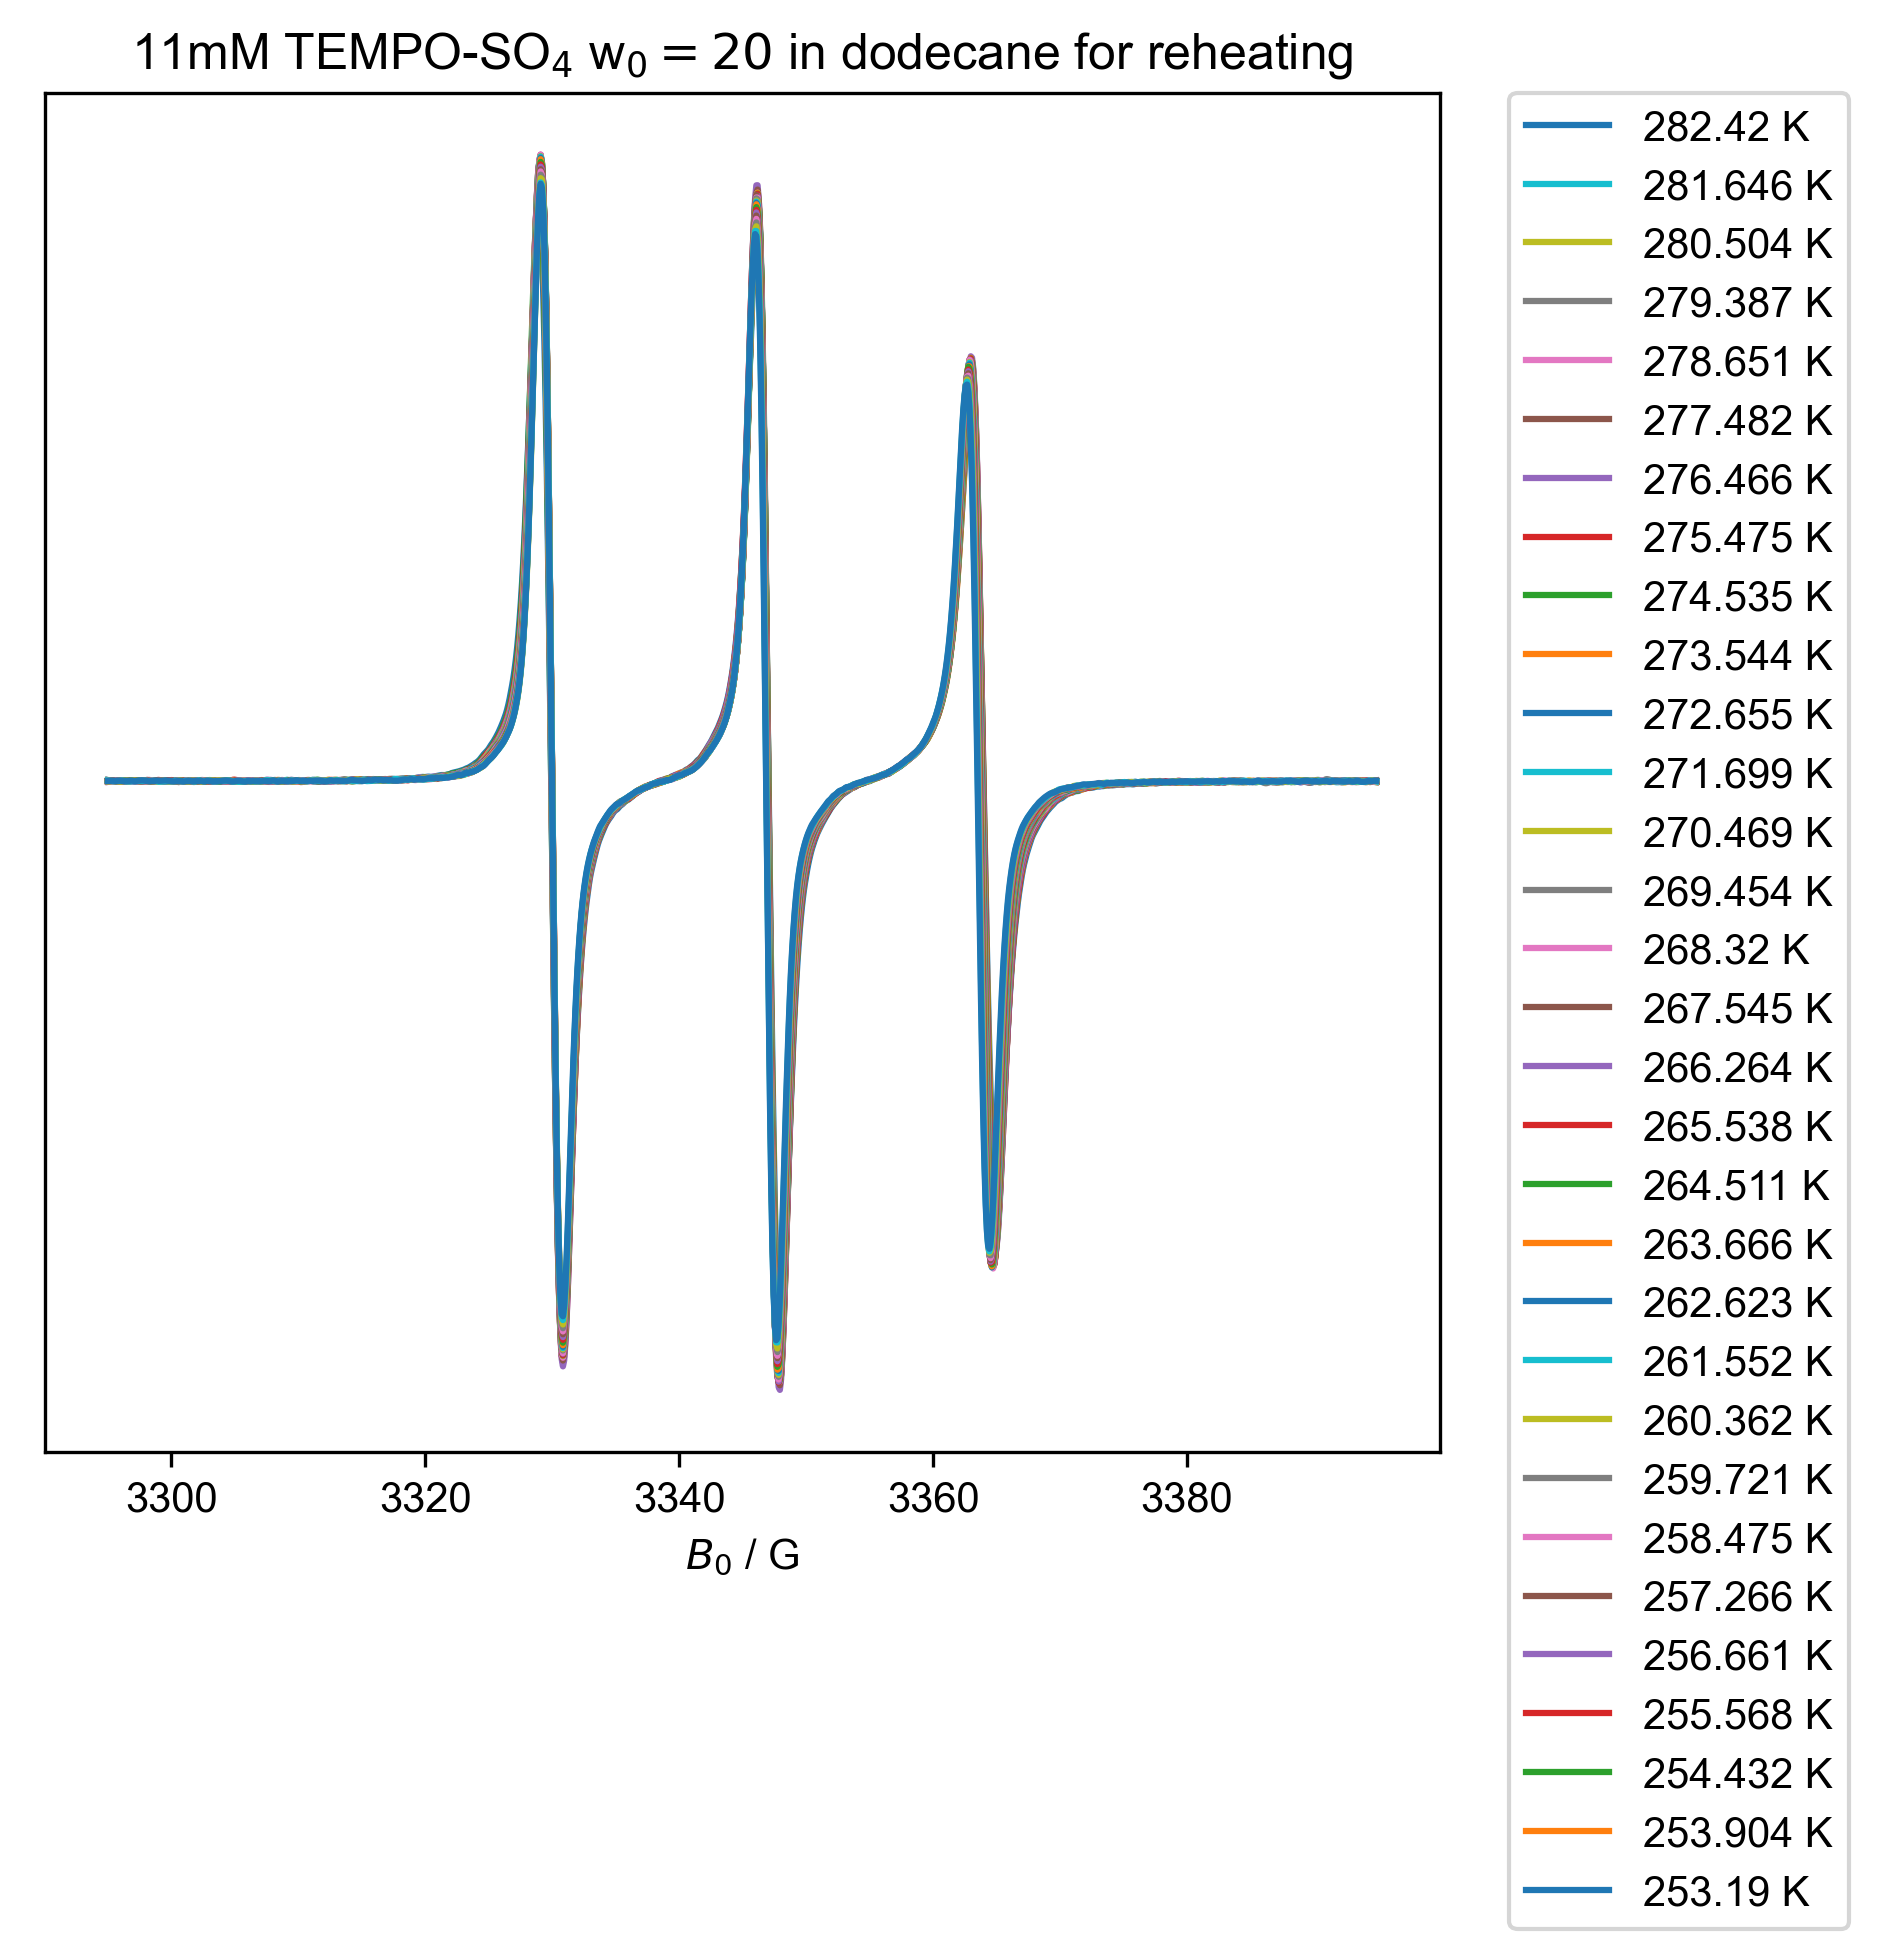

In [17]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("11mM TEMPO-SO$_4$ w$_0=20$ in dodecane for reheating", (200, 300))
 ]:
    this_d1 = d_reheating["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
#         offset += 2.2
#         offset += this_d1["Temperature", temp_ithis_dx].max()*1.8
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
#     fancy_legend()